### Загрузка датасета, анализ

In [1]:
!pip install -qU category_encoders
!pip install optuna
!pip install sktime
!pip install shap

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import category_encoders
from sklearn.linear_model import LinearRegression as lr
import xgboost as xgb
import lightgbm as lgb
import optuna
from sklearn.metrics import mean_squared_error as mse, mean_absolute_error as mae
from sktime.performance_metrics.forecasting import mean_absolute_percentage_error as mape
import seaborn as sns
from scipy import stats
import joblib

In [3]:
df = pd.read_csv('retail_sales.csv')

print('Информация о датафрейме:')
print(df.info(), end='\n\n')

print('Пропуски в данных:')
print(df.isna().sum())

Информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4565000 entries, 0 to 4564999
Data columns (total 8 columns):
 #   Column    Dtype  
---  ------    -----  
 0   date      object 
 1   store_id  object 
 2   item_id   object 
 3   sales     int64  
 4   price     float64
 5   promo     int64  
 6   weekday   int64  
 7   month     int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 278.6+ MB
None

Пропуски в данных:
date        0
store_id    0
item_id     0
sales       0
price       0
promo       0
weekday     0
month       0
dtype: int64


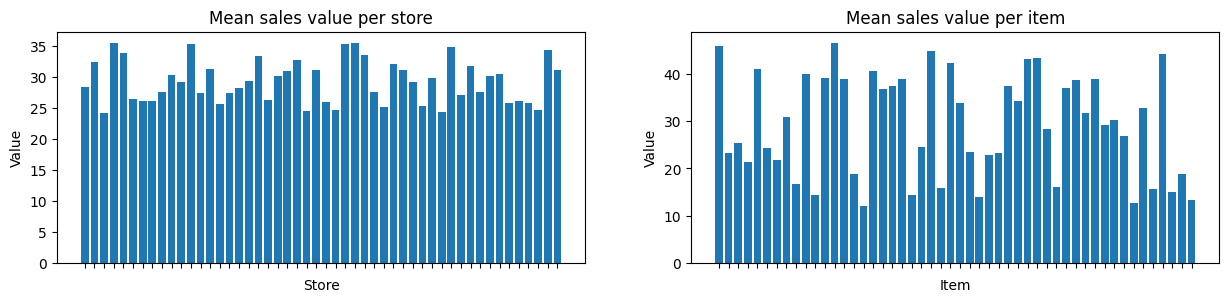

In [4]:
mean_store_target = df.groupby('store_id')['sales'].mean()
mean_item_target = df.groupby('item_id')['sales'].mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 3))

ax[0].bar(mean_store_target.index, mean_store_target)
ax[0].set_xticklabels([])
ax[0].set_xlabel('Store')
ax[0].set_ylabel('Value')
ax[0].set_title('Mean sales value per store')

ax[1].bar(mean_item_target.index, mean_item_target)
ax[1].set_xticklabels([])
ax[1].set_xlabel('Item')
ax[1].set_ylabel('Value')
ax[1].set_title('Mean sales value per item')

plt.show()

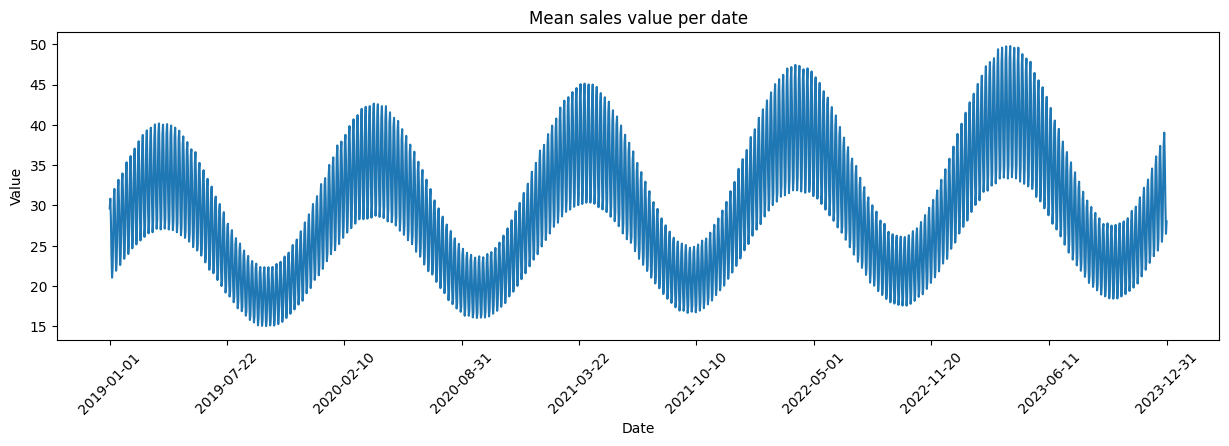

In [5]:
mean_date_target = df.groupby('date')['sales'].mean()

plt.figure(figsize=(15, 4))
plt.plot(mean_date_target.index, mean_date_target)
idx = np.linspace(0, len(mean_date_target.index) - 1, 10, dtype=int)
plt.xticks(mean_date_target.index[idx], rotation=45)
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Mean sales value per date')

plt.show()

### Формирование признаков

In [6]:
df['mean_item_sales'] = df.groupby(['item_id', 'store_id'])['sales'].transform('mean')
df['rolling_mean_item_sales_10'] = df.groupby(['item_id', 'store_id'])['sales'].transform(
    lambda x: x.rolling(10, min_periods=1).mean()
)

df['mean_store_sales'] = df.groupby(['store_id'])['sales'].transform('mean')

df['sales_lag_1'] = df.groupby(['item_id', 'store_id'])['sales'].shift(1)
df['sales_lag_3'] = df.groupby(['item_id', 'store_id'])['sales'].shift(3)
df['sales_lag_10'] = df.groupby(['item_id', 'store_id'])['sales'].shift(10)

df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['quarter'] = df['date'].dt.quarter
df['weekend'] = (df['weekday'] > 5).astype(int)

df = df.fillna(0)
df.head(3)

,date,store_id,item_id,sales,price,promo,weekday,month,mean_item_sales,rolling_mean_item_sales_10,mean_store_sales,sales_lag_1,sales_lag_3,sales_lag_10,year,quarter,weekend
0,2019-01-01,store_1,item_1,41,21.3,0,1,1,44.780942,41.000000,28.391982,0.0,0.0,0.0,2019,1,0
1,2019-01-02,store_1,item_1,53,21.3,0,2,1,44.780942,47.000000,28.391982,41.0,0.0,0.0,2019,1,0
2,2019-01-03,store_1,item_1,39,21.3,0,3,1,44.780942,44.333333,28.391982,53.0,0.0,0.0,2019,1,0


In [7]:
from sklearn.preprocessing import LabelEncoder

encode_store = LabelEncoder()
df['store_id_encoded'] = encode_store.fit_transform(df['store_id'])

encode_item = LabelEncoder()
df['item_id_encoded'] = encode_item.fit_transform(df['item_id'])

In [8]:
df = df.drop(columns=['date', 'store_id', 'item_id'])

df.head(3)

,sales,price,promo,weekday,month,mean_item_sales,rolling_mean_item_sales_10,mean_store_sales,sales_lag_1,sales_lag_3,sales_lag_10,year,quarter,weekend,store_id_encoded,item_id_encoded
0,41,21.3,0,1,1,44.780942,41.000000,28.391982,0.0,0.0,0.0,2019,1,0,0,0
1,53,21.3,0,2,1,44.780942,47.000000,28.391982,41.0,0.0,0.0,2019,1,0,0,0
2,39,21.3,0,3,1,44.780942,44.333333,28.391982,53.0,0.0,0.0,2019,1,0,0,0


### Разделение на тренировочную, валидационную и тестовую выборки

In [9]:
train = df[df['year'] < 2022]
X_train = train.drop(columns='sales')
y_train = train['sales']

val = df[df['year'] == 2022]
X_val = val.drop(columns='sales')
y_val = val['sales']

test = df[df['year'] >= 2023]
X_test = test.drop(columns='sales')
y_test = test['sales']

print(f'Примерное отношение размеров выборок: {int(train.shape[0] / test.shape[0])}:{int(val.shape[0] / test.shape[0])}:1')

Примерное отношение размеров выборок: 3:1:1


### Обучение моделей

In [10]:
models = {}

lr_model = lr()
lr_model.fit(X_train, y_train)

models['LR'] = lr_model

In [11]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_model = xgb.XGBRegressor(
    n_estimators=xgb_model.best_iteration,
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

models['XGBoost'] = xgb_model

In [12]:
def objective(trial):
    params = {
        'n_estimators': 500,
        'max_depth': trial.suggest_int('max_depth', 2, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.5),
        'min_child_weight': trial.suggest_int('min_child_weight', 10, 100),
        'random_state': 42,
        'n_jobs': -1,
        'early_stopping_rounds': 30,
        'verbosity': 0
    }

    model = xgb.XGBRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    y_pred = model.predict(X_val)
    rmse = np.sqrt(mse(y_val, y_pred))
    return rmse

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=10, show_progress_bar=True)

best_params = study.best_params

best_model = xgb.XGBRegressor(**best_params)
best_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

models['XGBoost + optuna'] = best_model

[I 2026-09-06 13:18:47,724] A new study created in memory with name: no-name-afcd1445-d595-4659-be57-a691a5bbaea9


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-09-06 13:19:19,392] Trial 0 finished with value: 3.11852998435251 and parameters: {'max_depth': 8, 'learning_rate': 0.2655617376690925, 'min_child_weight': 63}. Best is trial 0 with value: 3.11852998435251.
[I 2026-09-06 13:19:50,469] Trial 1 finished with value: 3.1242207890833242 and parameters: {'max_depth': 8, 'learning_rate': 0.30543135897395046, 'min_child_weight': 81}. Best is trial 0 with value: 3.11852998435251.
[I 2026-09-06 13:21:01,957] Trial 2 finished with value: 3.122465097371267 and parameters: {'max_depth': 5, 'learning_rate': 0.12330043127759731, 'min_child_weight': 38}. Best is trial 0 with value: 3.11852998435251.
[I 2026-09-06 13:21:34,097] Trial 3 finished with value: 3.1491182031575913 and parameters: {'max_depth': 5, 'learning_rate': 0.3348900554109678, 'min_child_weight': 53}. Best is trial 0 with value: 3.11852998435251.
[I 2026-09-06 13:23:17,294] Trial 4 finished with value: 3.151616387197335 and parameters: {'max_depth': 3, 'learning_rate': 0.149535

In [14]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=30)]
)

lgb_model = lgb.LGBMRegressor(
    n_estimators=lgb_model.best_iteration_,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

lgb_model.fit(X_train, y_train)

models['LightGBM'] = lgb_model

Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[223]	valid_0's l2: 9.71907


In [15]:
def objective(trial):
    params = {
        'n_estimators': 500,
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.5),
        'min_child_samples': trial.suggest_int('min_child_weight', 10, 100),
        'random_state': 42,
        'n_jobs': -1,
        'callbacks': [lgb.early_stopping(stopping_rounds=30)],
        'verbose': -1
    }

    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)]
    )

    y_pred = model.predict(X_val)
    rmse = np.sqrt(mse(y_val, y_pred))
    return rmse

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=10, show_progress_bar=True)

best_params = study.best_params

best_model = lgb.LGBMRegressor(**best_params)
best_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)]
)

models['LightGBM + optuna'] = best_model

[I 2026-09-06 13:44:10,318] A new study created in memory with name: no-name-7845a50c-dd2d-4d32-b8f7-fe17ae677efa


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-09-06 13:46:16,359] Trial 0 finished with value: 3.1630058845029665 and parameters: {'max_depth': 9, 'learning_rate': 0.4010185617039858, 'min_child_weight': 94}. Best is trial 0 with value: 3.1630058845029665.
[I 2026-09-06 13:48:18,956] Trial 1 finished with value: 3.167122548497621 and parameters: {'max_depth': 4, 'learning_rate': 0.3404928367562618, 'min_child_weight': 85}. Best is trial 0 with value: 3.1630058845029665.
[I 2026-09-06 13:50:20,750] Trial 2 finished with value: 3.1627234605867267 and parameters: {'max_depth': 4, 'learning_rate': 0.3738651890306987, 'min_child_weight': 74}. Best is trial 2 with value: 3.1627234605867267.
[I 2026-09-06 13:52:55,576] Trial 3 finished with value: 3.144913474523368 and parameters: {'max_depth': 6, 'learning_rate': 0.15185633771378246, 'min_child_weight': 63}. Best is trial 3 with value: 3.144913474523368.
[I 2026-09-06 13:54:38,638] Trial 4 finished with value: 3.166558994837186 and parameters: {'max_depth': 3, 'learning_rate': 0

### Сравнение моделей

In [16]:
def rolling_predict(model, X_train, X_test):
    last_train = X_train.iloc[-1].values
    test = X_test.values

    predictions = []

    idx_lag1 = X_train.columns.to_list().index('sales_lag_1')
    idx_lag3 = X_train.columns.to_list().index('sales_lag_3')
    idx_lag10 = X_train.columns.to_list().index('sales_lag_10')
    idx_item_rolling10 = X_train.columns.to_list().index('rolling_mean_item_sales_10')

    for i in range(X_test.shape[0]):
        row = test[i].copy()

        if i < 1:
            row[idx_lag1] = last_train[idx_lag1]
        else:
            row[idx_lag1] = predictions[-1]

        if i < 3:
            row[idx_lag3] = last_train[idx_lag3]
        else:
            row[idx_lag3] = predictions[-3]

        if i < 10:
            row[idx_lag10] = last_train[idx_lag10]
        else:
            row[idx_lag10] = predictions[-10]

        if i < 10:
            row[idx_item_rolling10] = last_train[idx_item_rolling10]
        else:
            row[idx_item_rolling10] = np.mean(predictions[-10:])

        pred = model.predict(row.reshape(1, -1))[0]
        predictions.append(pred)

    return np.array(predictions)

In [18]:
import warnings
warnings.filterwarnings('ignore')

In [19]:
results = pd.DataFrame(columns=['model_name', 'RMSE', 'MAE', 'SMAPE'])

for name, model in models.items():
  y_pred = rolling_predict(model, X_train, X_test)

  rmse_val = np.sqrt(mse(y_test, y_pred))
  mae_val = mae(y_test, y_pred)
  smape_val = mape(y_test, y_pred, symmetric=True)

  results.loc[len(results)] = [name, rmse_val, mae_val, smape_val]

results

,model_name,RMSE,MAE,SMAPE
0,LR,13.493943,10.953147,0.351605
1,XGBoost,6.465771,4.825814,0.167767
2,XGBoost + optuna,5.689795,4.293324,0.149198
3,LightGBM,6.261140,4.586844,0.159682
4,LightGBM + optuna,8.336248,6.086168,0.205788


### Анализ лучшей (XGBoost с подобранными гиперпараметрами)

Mean residuals: 3.3824382568432534
Std: 4.575245554423494


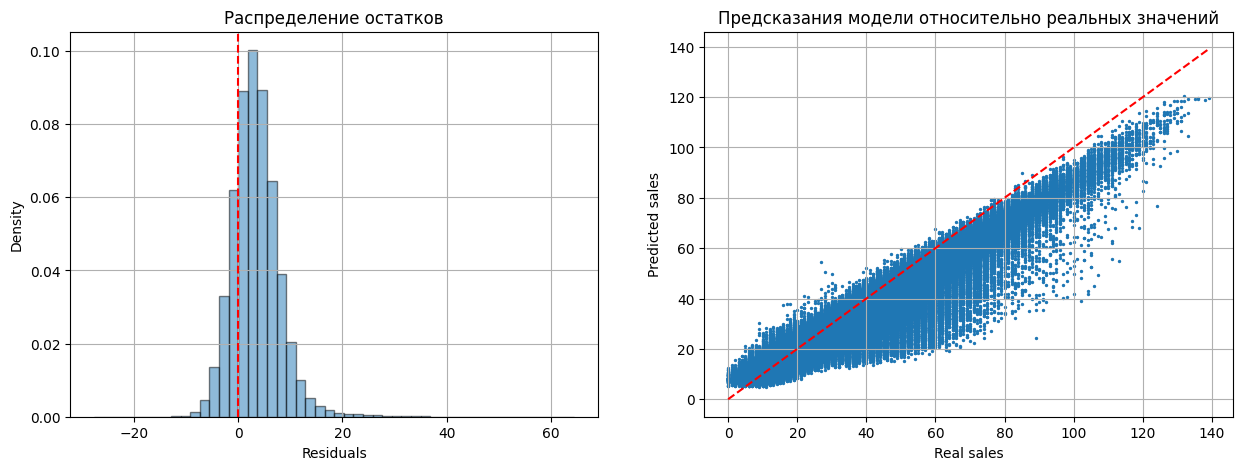

In [20]:
model = models['XGBoost + optuna']

y_pred = rolling_predict(model, X_train, X_test)
residuals = y_test - y_pred

print(f'Mean residuals: {np.mean(residuals)}')
print(f'Std: {np.std(residuals)}')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(residuals, bins=50, density=True, alpha=0.5, edgecolor='black')
ax[0].axvline(0, color='red', linestyle='--')
ax[0].set_xlabel('Residuals')
ax[0].set_ylabel('Density')
ax[0].set_title('Распределение остатков')
ax[0].grid(True)

ax[1].scatter(y_test, y_pred, s=2)
ax[1].plot([0, np.max(y_test)], [0, np.max(y_test)], color='red', linestyle='--')
ax[1].set_xlabel('Real sales')
ax[1].set_ylabel('Predicted sales')
ax[1].set_title('Предсказания модели относительно реальных значений')
ax[1].grid(True)

plt.show()

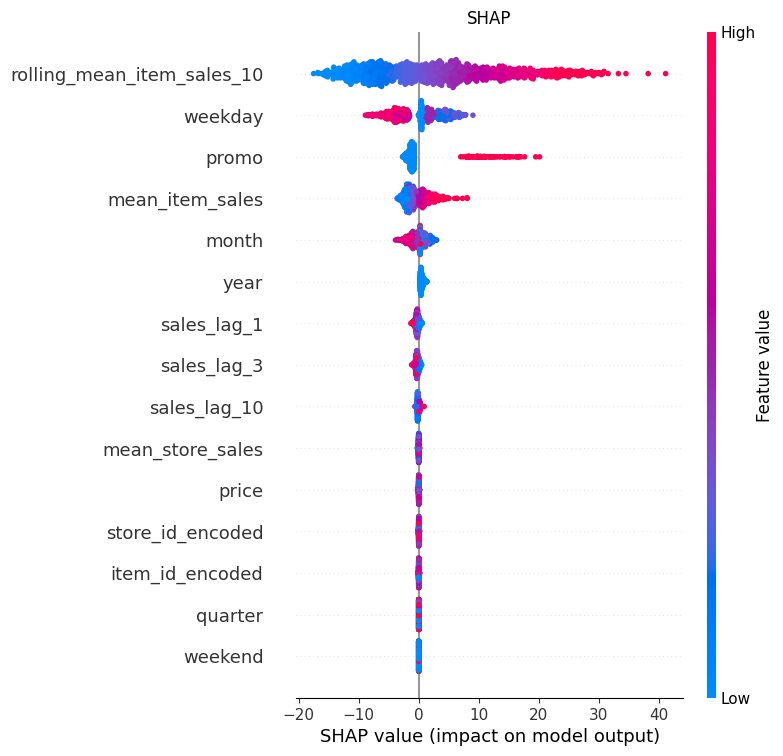

In [23]:
import shap

idx = np.random.choice(len(X_test), size=1000, replace=False)
X_sample = X_test.iloc[idx]

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

plt.figure(figsize=(8, 4))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title('SHAP')
plt.show()

In [24]:
joblib.dump(model, 'best_model.pkl')

['best_model.pkl']

Mean residuals: 2.7171897110351133
Std: 4.57524555442349


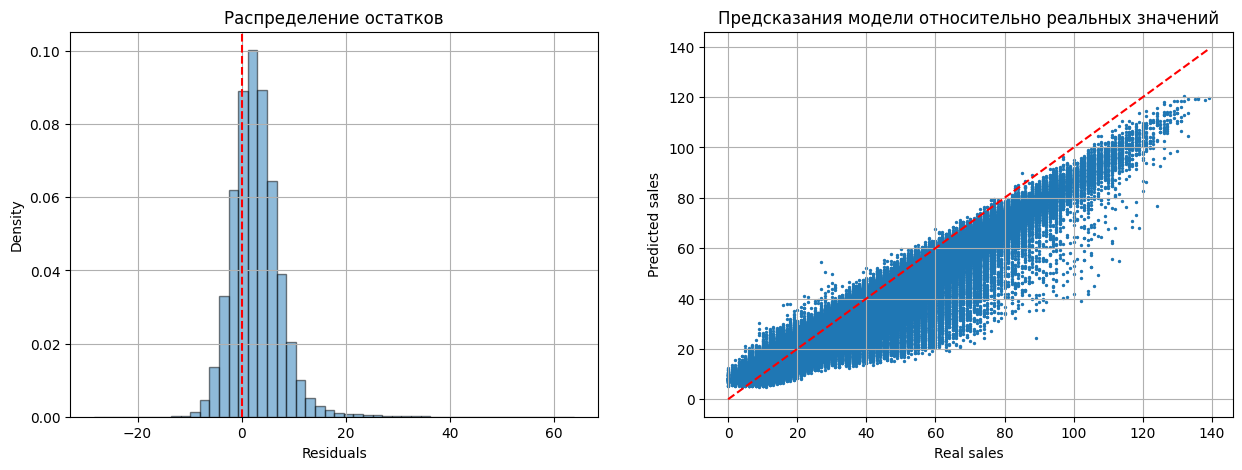

In [25]:
y_pred_val = model.predict(X_val)
bias = np.mean(y_val - y_pred_val)

y_pred_corrected = y_pred + bias
residuals_corrected = y_test - y_pred_corrected

print(f'Mean residuals: {np.mean(residuals)}')
print(f'Std: {np.std(residuals)}')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].hist(residuals, bins=50, density=True, alpha=0.5, edgecolor='black')
ax[0].axvline(0, color='red', linestyle='--')
ax[0].set_xlabel('Residuals')
ax[0].set_ylabel('Density')
ax[0].set_title('Распределение остатков')
ax[0].grid(True)

ax[1].scatter(y_test, y_pred, s=2)
ax[1].plot([0, np.max(y_test)], [0, np.max(y_test)], color='red', linestyle='--')
ax[1].set_xlabel('Real sales')
ax[1].set_ylabel('Predicted sales')
ax[1].set_title('Предсказания модели относительно реальных значений')
ax[1].grid(True)

plt.show()

In [26]:
rmse_val = np.sqrt(mse(y_test, y_pred_corrected))
mae_val = mae(y_test, y_pred_corrected)
smape_val = mape(y_test, y_pred_corrected, symmetric=True)

results.loc[len(results)] = ['XGBoost + optuna + bias', rmse_val, mae_val, smape_val]

results

,model_name,RMSE,MAE,SMAPE
0,LR,13.493943,10.953147,0.351605
1,XGBoost,6.465771,4.825814,0.167767
2,XGBoost + optuna,5.689795,4.293324,0.149198
3,LightGBM,6.261140,4.586844,0.159682
4,LightGBM + optuna,8.336248,6.086168,0.205788
5,XGBoost + optuna + bias,5.321277,3.947677,0.137919
